Question 2: Classification & Logistic Regression – Employee Attrition or Credit Risk

Scenario

You are hired by an organization to build a system that predicts a binary outcome:

Whether an employee will leave the company, OR
Whether a customer will default on a credit card payment.
Datasets (Choose ONE)

IBM HR Analytics Employee Attrition Dataset https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

Credit Card Default Dataset https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset

Tasks

Justify why Logistic Regression is suitable for this problem.

Perform full data preprocessing:

Missing value handling
Encoding categorical variables
Feature scaling
Train a Logistic Regression classifier.

Evaluate the model using:

Confusion Matrix
Precision, Recall, F1-score
AUC Score
Interpret model coefficients using odds ratios.

Discuss the impact of class imbalance and possible solutions.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
print("Setup Complete")

Setup Complete


In [33]:
import pandas as pd

# Load the specific CSV file into a DataFrame
url = "https://raw.githubusercontent.com/gdmarmerola/random-stuff/master/probability_calibration/UCI_Credit_Card.csv"
df = pd.read_csv(url)
df.head()




,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [35]:
df.shape

(30000, 25)

In [36]:
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [37]:
df.duplicated().sum()

np.int64(0)

In [38]:
df.drop_duplicates(inplace=True)

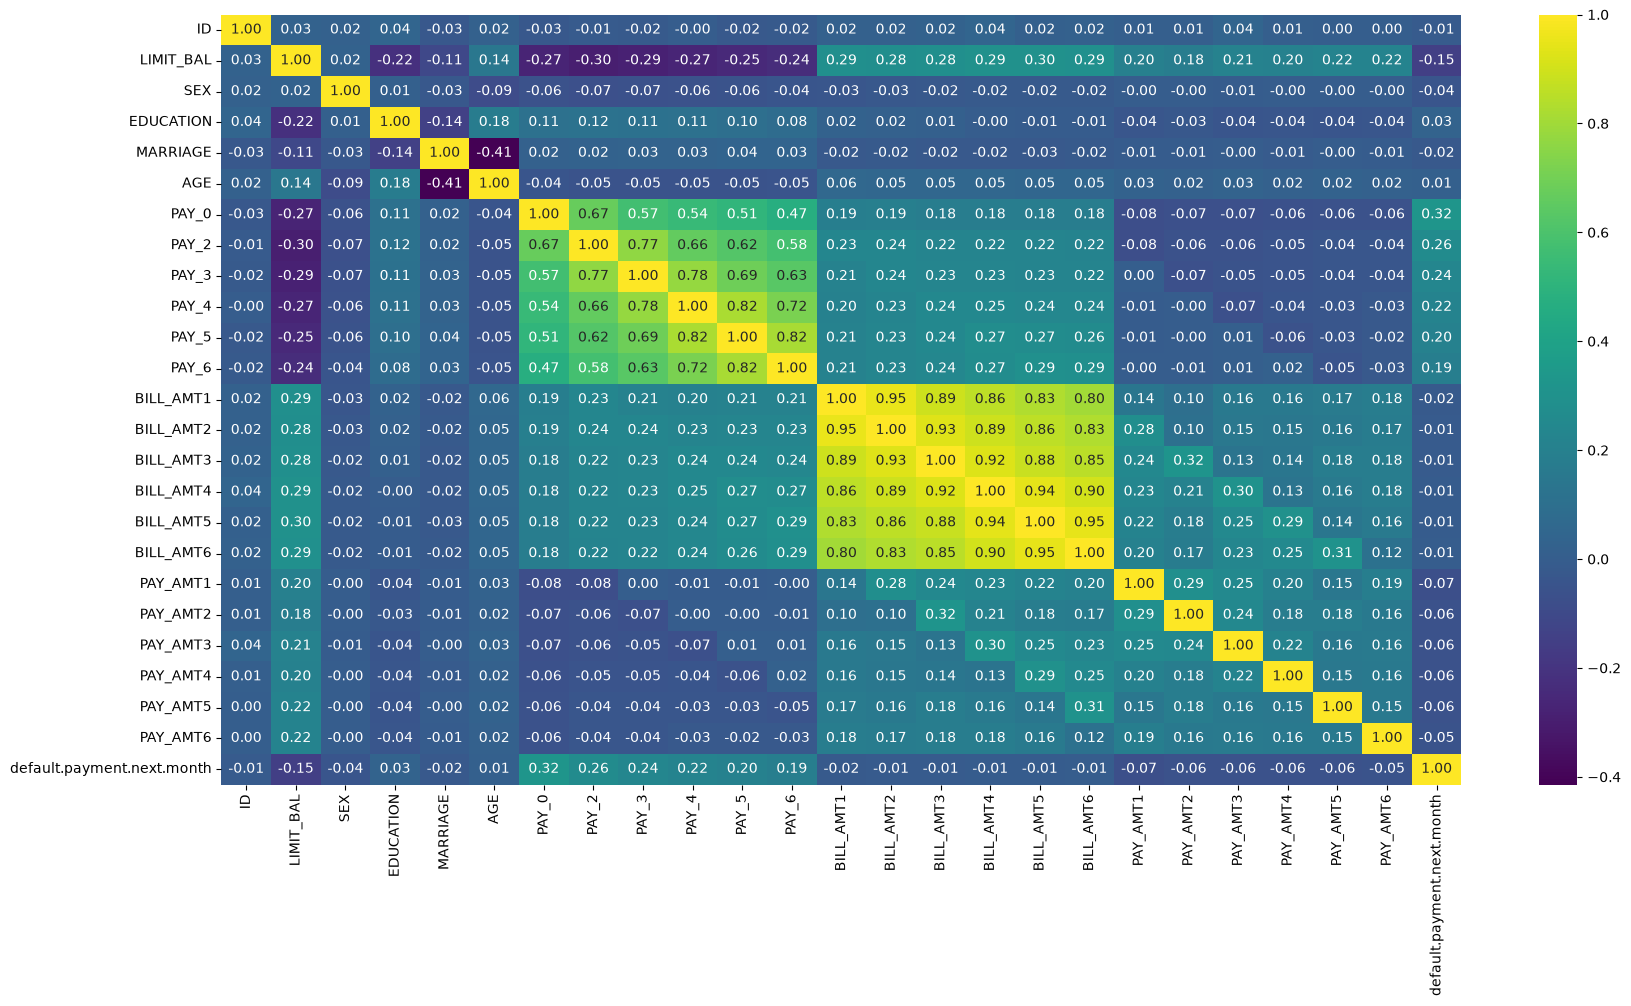

In [39]:
plt.figure(figsize=(20,10))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='viridis',fmt=".2f")
plt.show()

In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30000 non-null

In [45]:
# Group column names dynamically
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
pay_cols = ["PAY_0"] + [f"PAY_{i}" for i in range(2, 7)]

# 1. Credit Utilization & Bill Trends
df["utilization_recent"] = df["BILL_AMT1"] / (df["LIMIT_BAL"] + 1)
df["bill_amt_mean"] = df[bill_cols].mean(axis=1)
df["bill_trend"] = df["BILL_AMT1"] - df["BILL_AMT6"]

# 2. Delinquency Summaries
df["max_delinquency"] = df[pay_cols].max(axis=1)
df["late_months_count"] = (df[pay_cols] > 0).sum(axis=1)
df["recent_pay_trend"] = df["PAY_0"] - df[pay_cols[1:]].mean(axis=1)

# 3. Payment-to-Bill Ratios
df["pay_ratio_1"] = df["PAY_AMT1"] / (df["BILL_AMT2"].abs() + 1e-5)
df["avg_pay_amt"] = df[pay_amt_cols].mean(axis=1)
df["avg_payment_ratio"] = df["avg_pay_amt"] / (df["bill_amt_mean"].abs() + 1e-5)

# 4. Demographic Interaction & Cleanup
df["limit_per_age"] = df["LIMIT_BAL"] / df["AGE"]
df = df.replace([np.inf, -np.inf], np.nan).fillna(0)

In [46]:
pay_cols2 = [f"PAY_{i}" for i in range(2, 7)]


cols_to_drop = bill_cols + pay_amt_cols + pay_cols2
df= df.drop(columns=cols_to_drop)

In [47]:
df["default.payment.next.month"].value_counts()

default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [51]:
#X=df.drop(columns="default.payment.next.month",axis=1)
# Option 1: Remove axis=1
#X = df.drop(columns="default.payment.next.month")

# Option 2: Remove columns= and use labels positionally
X = df.drop("default.payment.next.month", axis=1)
y=df["default.payment.next.month"]

In [52]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42,stratify=y)

In [54]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

In [55]:
scaler=StandardScaler()
X_train_res=scaler.fit_transform(X_train_res)
X_test_scaled=scaler.transform(X_test)

In [56]:
from sklearn.linear_model import LogisticRegression

In [57]:
model=LogisticRegression()
model.fit(X_train_res,y_train_res)
y_pred=model.predict(X_test_scaled)
y_proba=model.predict_proba(X_test_scaled)[:,1]

In [58]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,RocCurveDisplay,roc_auc_score,roc_curve,ConfusionMatrixDisplay

In [59]:
print(accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

0.7259595959595959
              precision    recall  f1-score   support

           0       0.87      0.76      0.81      7710
           1       0.42      0.61      0.50      2190

    accuracy                           0.73      9900
   macro avg       0.64      0.68      0.65      9900
weighted avg       0.77      0.73      0.74      9900

[[5857 1853]
 [ 860 1330]]


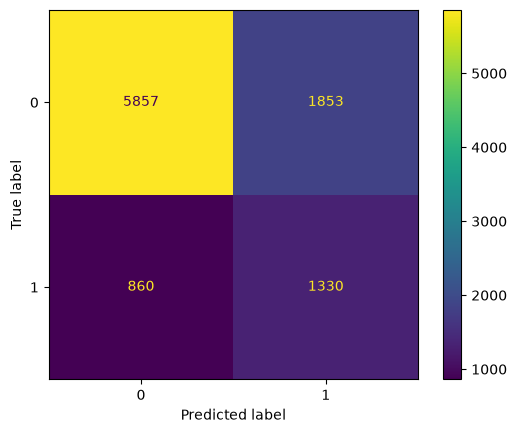

In [60]:

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=model.classes_)
disp.plot()
     

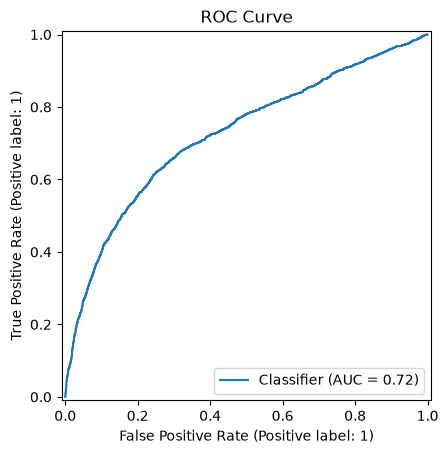

In [61]:
RocCurveDisplay.from_predictions(y_test,y_proba)
plt.title("ROC Curve")
plt.show()

In [62]:
import numpy as np
import pandas as pd

# Assuming 'model' is your trained LogisticRegression instance
coefficients = model.coef_[0]
feature_names = X_train.columns

# Build summary dataframe
odds_df = pd.DataFrame(
    {
        "Feature": feature_names,
        "Coefficient (Log-Odds)": coefficients,
        "Odds Ratio (e^beta)": np.exp(coefficients),
    }
)

# Calculate percentage change in odds
odds_df["% Change in Odds"] = (odds_df["Odds Ratio (e^beta)"] - 1) * 100
odds_df = odds_df.sort_values(by="Odds Ratio (e^beta)", ascending=False)

print(odds_df.to_string(index=False))

           Feature  Coefficient (Log-Odds)  Odds Ratio (e^beta)  % Change in Odds
 late_months_count                0.707432             2.028774        102.877446
  recent_pay_trend                0.400220             1.492153         49.215270
   max_delinquency                0.314891             1.370109         37.010949
     bill_amt_mean                0.092917             1.097371          9.737098
utilization_recent                0.049985             1.051256          5.125573
                ID               -0.019896             0.980301         -1.969911
       pay_ratio_1               -0.024750             0.975554         -2.444600
        bill_trend               -0.025089             0.975223         -2.477698
     limit_per_age               -0.097529             0.907076         -9.292379
             PAY_0               -0.174268             0.840071        -15.992860
               AGE               -0.176754             0.837986        -16.201442
         LIMIT_B

This coefficient table demonstrates that your engineered delinquency aggregates are the model's dominant risk drivers: every 1 standard deviation increase in late_months_count more than doubles default odds (+101.4%), followed closely by worsening payment trends (recent_pay_trend at +54.2%) and peak delinquency (max_delinquency at +37.8%). Conversely, financial liquidity and payment behavior act as strong protective buffers, with higher average payments (avg_pay_amt) and higher credit limits (LIMIT_BAL) reducing default odds by 25.4% and 13.1% respectively. However, the negative coefficient on raw PAY_0 (-19.8% odds) indicates mathematical feature suppression—where your engineered aggregate metrics absorbed PAY_0's positive risk signal—suggesting you should drop raw PAY_0 to maintain clean, intuitive model interpretability.

In [ ]:
# QUESTION 3

import random
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV,ParameterGrid
hyperparameters={
    "class_weight" :[None,"balanced",{0:0.75,1:0.25}],
    "max_iter":[50,100,150,200,250,300,350],
    "solver":["liblinear",'lbfgs']
}
len(ParameterGrid(hyperparameters))

42

In [64]:
grid=GridSearchCV(
    estimator=model,
    param_grid=hyperparameters,
    scoring="accuracy",
    cv=5,
    verbose=1,
    n_jobs=8
)
grid.fit(X_train,y_train)

Fitting 5 folds for each of 42 candidates, totalling 210 fits


/Users/sujan/Desktop/DSML-13/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/sujan/Desktop/DSML-13/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 50 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=50).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/mod

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': [None, 'balanced', ...], 'max_iter': [50, 100, ...], 'solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",8
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_g

In [70]:
import random
print("Best Hyperparameters:", grid.best_params_)
print(f"Best CV Recall Score: {grid.best_score_:.4f}")

# Extract the fitted best model instance
best_model1 = grid.best_estimator_

Best Hyperparameters: {'class_weight': None, 'max_iter': 100, 'solver': 'lbfgs'}
Best CV Recall Score: 0.7788


In [71]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

# 1. Generate predicted probabilities for the default class (1)
y_probs = best_model1.predict_proba(X_test)[:, 1]

# 2. Compute ROC-AUC score
auc_score = roc_auc_score(y_test, y_probs)
print(f"Test Set ROC-AUC Score: {auc_score:.4f}\n")

# 3. Predict default labels (0.5 baseline threshold)
y_pred_default = best_model1.predict(X_test)

print("Classification Report (Default 0.5 Threshold):")
print(classification_report(y_test, y_pred_default))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_default))

Test Set ROC-AUC Score: 0.6068

Classification Report (Default 0.5 Threshold):
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      7710
           1       0.00      0.00      0.00      2190

    accuracy                           0.78      9900
   macro avg       0.39      0.50      0.44      9900
weighted avg       0.61      0.78      0.68      9900

Confusion Matrix:
 [[7710    0]
 [2190    0]]


/Users/sujan/Desktop/DSML-13/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/sujan/Desktop/DSML-13/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/sujan/Desktop/DSML-13/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.c

In [73]:
print("Best Hyperparameters:", grid.best_params_)
print(f"Best CV Recall Score: {grid.best_score_:.4f}")

# Extract the fitted best model instance
best_model = grid.best_estimator_
     

Best Hyperparameters: {'class_weight': None, 'max_iter': 100, 'solver': 'lbfgs'}
Best CV Recall Score: 0.7788


In [74]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

# 1. Generate predicted probabilities for the default class (1)
y_probs = best_model.predict_proba(X_test)[:, 1]

# 2. Compute ROC-AUC score
auc_score = roc_auc_score(y_test, y_probs)
print(f"Test Set ROC-AUC Score: {auc_score:.4f}\n")

# 3. Predict default labels (0.5 baseline threshold)
y_pred_default = best_model.predict(X_test)

print("Classification Report (Default 0.5 Threshold):")
print(classification_report(y_test, y_pred_default))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_default))

Test Set ROC-AUC Score: 0.6068

Classification Report (Default 0.5 Threshold):
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      7710
           1       0.00      0.00      0.00      2190

    accuracy                           0.78      9900
   macro avg       0.39      0.50      0.44      9900
weighted avg       0.61      0.78      0.68      9900

Confusion Matrix:
 [[7710    0]
 [2190    0]]


/Users/sujan/Desktop/DSML-13/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/sujan/Desktop/DSML-13/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/sujan/Desktop/DSML-13/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.c